<a href="https://colab.research.google.com/github/Pal2786/Data-Analysis-Portfolio/blob/main/projects/sql-operational-analysis/SQL_Operational_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import sqlite3

# Download fictional datasets from GitHub
base = (
    "https://raw.githubusercontent.com/"
    "Pal2786/Data-Analysis-Portfolio/main/"
    "projects/sql-operational-analysis/"
)

cases = pd.read_csv(base + "cases.csv")
teams = pd.read_csv(base + "teams.csv")

# Create a temporary SQL database
conn = sqlite3.connect(":memory:")

cases.to_sql("cases", conn, index=False, if_exists="replace")
teams.to_sql("teams", conn, index=False, if_exists="replace")

# Analyse workload by team using SQL
query = """
SELECT
    t.team_name,
    COUNT(c.case_id) AS total_cases,
    SUM(
        CASE
            WHEN c.resolved_date IS NULL THEN 1
            ELSE 0
        END
    ) AS unresolved_cases,
    t.active_processors
FROM cases AS c
INNER JOIN teams AS t
    ON c.team_id = t.team_id
GROUP BY
    t.team_name,
    t.active_processors
ORDER BY t.team_name;
"""

results = pd.read_sql_query(query, conn)
display(results)


,team_name,total_cases,unresolved_cases,active_processors
0,Claims Review,4,1,3
1,Complex Cases,4,2,2
2,Email Operations,4,1,4


In [2]:


query2 = """
SELECT
    t.team_name,
    COUNT(*) AS total_cases,

    SUM(
        CASE WHEN c.resolved_date IS NULL
        THEN 1 ELSE 0 END
    ) AS unresolved_cases,

    ROUND(AVG(
        julianday(c.resolved_date) -
        julianday(c.received_date)
    ), 1) AS avg_resolution_days,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN c.resolved_date IS NOT NULL
                AND (
                    julianday(c.resolved_date) -
                    julianday(c.received_date)
                ) <= c.sla_target_days
                THEN 1 ELSE 0
            END
        ) /
        NULLIF(SUM(
            CASE WHEN c.resolved_date IS NOT NULL
            THEN 1 ELSE 0 END
        ), 0), 1
    ) AS sla_met_pct

FROM cases c
INNER JOIN teams t
    ON c.team_id = t.team_id

GROUP BY t.team_name
ORDER BY t.team_name;
"""

results2 = pd.read_sql_query(query2, conn)
display(results2)


,team_name,total_cases,unresolved_cases,avg_resolution_days,sla_met_pct
0,Claims Review,4,1,6.0,33.3
1,Complex Cases,4,2,3.0,100.0
2,Email Operations,4,1,3.0,100.0


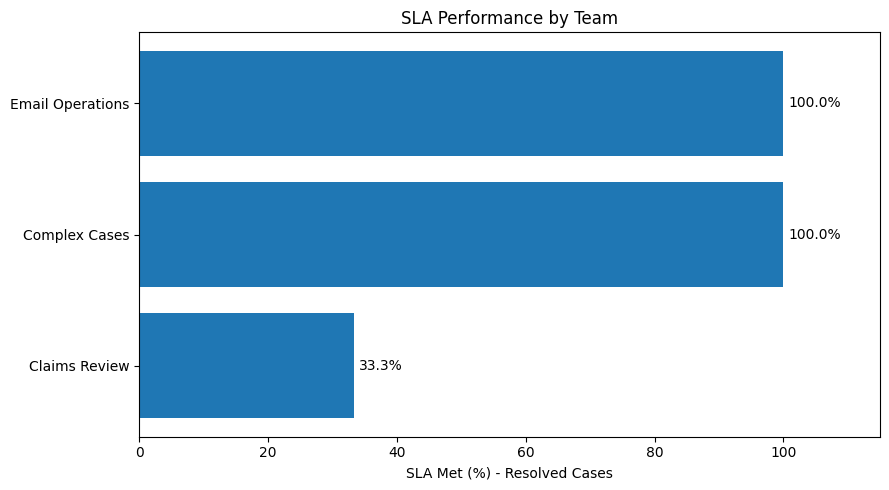

In [3]:

import matplotlib.pyplot as plt

# Visualise SLA performance by team
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    results2["team_name"],
    results2["sla_met_pct"]
)

ax.set_title("SLA Performance by Team")
ax.set_xlabel("SLA Met (%) - Resolved Cases")
ax.set_xlim(0, 115)

# Add percentage labels
ax.bar_label(bars, fmt="%.1f%%", padding=4)

plt.tight_layout()

# Save chart for GitHub portfolio
plt.savefig(
    "sql_team_sla_performance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


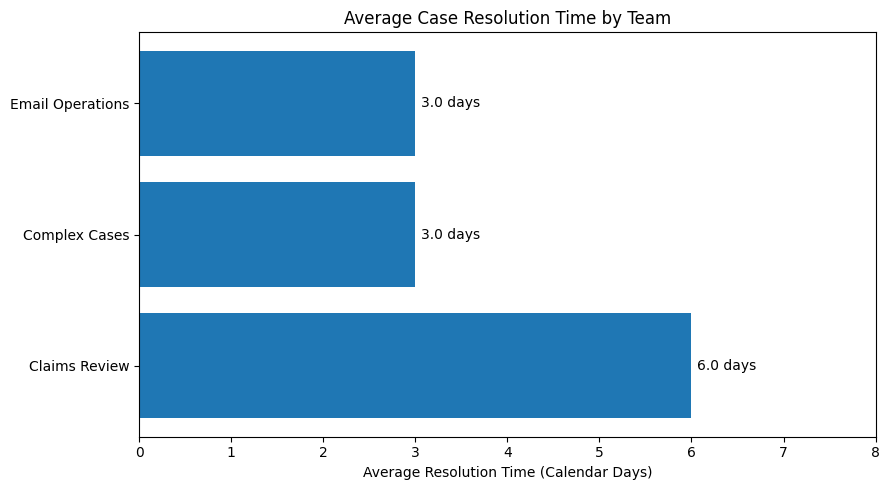

In [4]:

import matplotlib.pyplot as plt

# Compare average resolution time by team
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    results2["team_name"],
    results2["avg_resolution_days"]
)

ax.set_title("Average Case Resolution Time by Team")
ax.set_xlabel("Average Resolution Time (Calendar Days)")
ax.set_xlim(0, 8)

# Display values on each bar
ax.bar_label(bars, fmt="%.1f days", padding=4)

plt.tight_layout()

# Save chart as an image
plt.savefig(
    "sql_average_resolution_time.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
